In [1]:
!pip install vit_keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.2 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report
from vit_keras import vit

2025-08-27 07:50:06.293137: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756281006.647902      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756281006.750898      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:


# Set dataset path
base_dir = '/kaggle/input/flood-dataset/data'

# Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [4]:

# Load pre-trained Vision Transformer (ViT-B/16)
base_model = vit.vit_l32(
    image_size=IMG_SIZE,
    pretrained=True,
    include_top=False,
    pretrained_top=False
)

# Freeze the base model layers
base_model.trainable = False

# Add custom classification layers
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)
x = Dense(1024, activation='relu')(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes: Flood, Non-Flood

# Create the new model
model = Model(inputs=inputs, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10  # Consistent with original notebook
)

I0000 00:00:1756281076.729913      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1756281076.730745      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


1226658854/1226658854 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step


/usr/local/lib/python3.11/dist-packages/vit_keras/utils.py:85: UserWarning: Resizing position embeddings from 12, 12 to 7, 7
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/10


I0000 00:00:1756281144.144752     125 service.cc:148] XLA service 0x79dbbc0032c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756281144.146413     125 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1756281144.146432     125 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1756281148.995620     125 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1756281182.899792     125 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11/11 ━━━━━━━━━━━━━━━━━━━━ 121s 5s/step - accuracy: 0.7115 - loss: 0.5231 - val_accuracy: 0.9383 - val_loss: 0.1684
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - accuracy: 0.9729 - loss: 0.0992 - val_accuracy: 0.9506 - val_loss: 0.0989
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 442ms/step - accuracy: 0.9940 - loss: 0.0373 - val_accuracy: 0.9877 - val_loss: 0.0773
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 402ms/step - accuracy: 0.9952 - loss: 0.0246 - val_accuracy: 0.9877 - val_loss: 0.0682
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 414ms/step - accuracy: 0.9977 - loss: 0.0192 - val_accuracy: 0.9630 - val_loss: 0.0680
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 401ms/step - accuracy: 1.0000 - loss: 0.0175 - val_accuracy: 0.9877 - val_loss: 0.0672
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 416ms/step - accuracy: 0.9945 - loss: 0.0145 - val_accuracy: 0.9630 - val_loss: 0.0605
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 396ms/step - accuracy: 1.0000 - loss: 0.0056 - val_accuracy: 0.9753 - val_l

In [5]:


# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.9742 - loss: 0.0872  
Test Accuracy: 0.97


In [ ]:

# Save the model
model.save('/content/drive/MyDrive/pre_trained_vit_b16_model.keras')
print("Model saved successfully to Google Drive.")

Model saved successfully to Google Drive.


3/3 ━━━━━━━━━━━━━━━━━━━━ 91s 22s/step


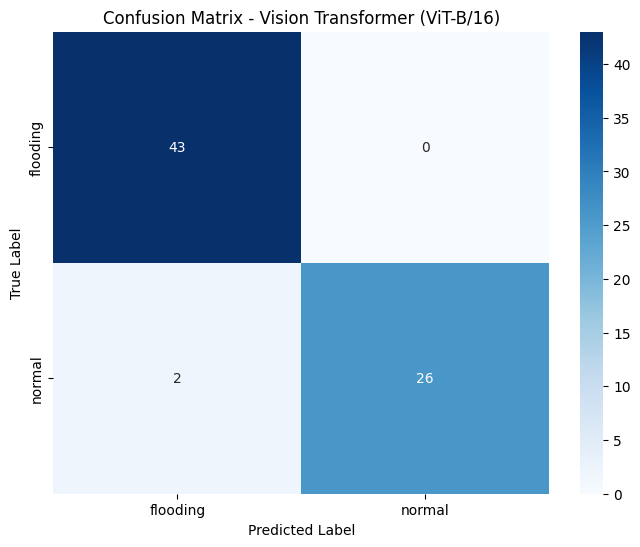

In [ ]:

# Generate and plot confusion matrix
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Vision Transformer (ViT-B/16)')
plt.show()



In [ ]:
# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

    flooding       0.96      1.00      0.98        43
      normal       1.00      0.93      0.96        28

    accuracy                           0.97        71
   macro avg       0.98      0.96      0.97        71
weighted avg       0.97      0.97      0.97        71

